# 응용 05. Dropout 확률 비교와 best epoch 해석

2026-10-30 실습 기록 · 원본: `../05_dropout.py`


## 0. 작업 전 준비사항
PyTorch, pandas, Matplotlib이 설치된 커널에서 **Run All(모두 실행)**로 실행합니다. 저장소 루트, `02_응용`, `docs` 폴더에서 실행할 수 있습니다.

이번 기록은 실제 실습 코드의 **80 epochs**를 실행한 결과입니다. README의 예상 출력은 이번 측정 결과와 구분합니다. 코드는 CUDA 사용 가능 여부에 따라 장치를 선택하며, 이번 검증은 CPU에서 수행했습니다. 장치나 라이브러리 버전에 따라 수치는 달라질 수 있습니다.

## 1. 비교 목적과 고정 조건
`p=0.0`과 `p=0.3`만 다르게 설정해 검증 손실을 비교합니다.

| 항목 | 설정 |
| --- | --- |
| 모델 | Linear(2,32) → ReLU → Dropout(p) → Linear(32,32) → ReLU → Dropout(p) → Linear(32,2) |
| Optimizer | AdamW, lr=0.01, weight_decay=0.0 |
| 학습 | 80 epochs, batch_size=32 |
| 난수 | 후보마다 초기화 seed=42, shuffle Generator seed=43 |
| 데이터 | points.csv의 train/valid 사용. test는 평가에 사용하지 않음 |
| 손실 | CrossEntropyLoss |

후보마다 모델·Optimizer·DataLoader를 새로 만듭니다. Dropout 난수와 데이터 순서의 난수를 분리해 배치 순서를 동일하게 유지합니다. `p=0`은 항상 활성값을 유지하며 `p=0.3`은 학습 중 원소를 확률 0.3으로 제거하고 남은 값을 `1/0.7`배로 조정합니다.


In [1]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/practice-matplotlib")
import runpy
import pandas as pd
import torch

candidates = [Path.cwd(), Path.cwd().parent,
              Path.cwd() / "20261030" / "02_응용"]
base = next((p for p in candidates if (p / "05_dropout.py").is_file()), None)
if base is None:
    raise FileNotFoundError("저장소 루트, 02_응용 또는 docs에서 실행하세요.")
base = base.resolve()
print("PyTorch:", torch.__version__)
print("실행 장치:", "cuda:0" if torch.cuda.is_available() else "cpu")


PyTorch: 2.14.0+cu130
실행 장치: cpu


## 2. A05 설정과 학습 실행
실습 파일에 작성한 후보는 다음과 같습니다.

```python
configs = [
    {'name': 'dropout0.0', 'lr': 0.01, 'dropout': 0.0},
    {'name': 'dropout0.3', 'lr': 0.01, 'dropout': 0.3}
]
```

아래 셀은 원본 파일을 실행해 CSV·PNG를 다시 생성합니다. 매 epoch 학습 전 `model.train()`을 호출하고, epoch 종료 후 `model.eval()`과 `torch.no_grad()`로 train·valid를 모두 측정합니다. 따라서 `train_loss_eval`은 학습 중 마스크가 적용된 배치 손실이 아니라, **epoch 종료 시 Dropout을 끈 모델의 학습 데이터 손실**입니다.


In [2]:
run_state = runpy.run_path(str(base / "05_dropout.py"), run_name="__main__")


dropout0.0 best epoch: 78 best valid loss: 0.006114
dropout0.3 best epoch: 76 best valid loss: 0.019034
생성: outputs/05_*.csv, *.png / test 미사용


## 3. best valid loss와 best epoch 비교
각 후보의 80개 `valid_loss` 중 최소값을 **best valid loss**, 그 행의 epoch를 **best epoch**로 정합니다. 최소값이 여러 번이면 `idxmin()`이 처음 등장한 행을 고릅니다. 최종 epoch나 최고 정확도를 기준으로 고른 결과가 아닙니다.


In [3]:
out = base / "outputs"
comparison = pd.read_csv(out / "05_comparison.csv")
print(comparison[["dropout", "best_epoch", "best_valid_loss", "valid_acc_at_best",
                  "last_train_loss_eval", "last_valid_loss"]].to_string(index=False, float_format=lambda x: f"{x:.6f}"))
histories = {p: pd.read_csv(out / f"05_dropout{p:.1f}_history.csv") for p in (0.0, 0.3)}


 dropout  best_epoch  best_valid_loss  valid_acc_at_best  last_train_loss_eval  last_valid_loss
0.000000          78         0.006114           1.000000              0.079643         0.036195
0.300000          76         0.019034           0.987500              0.032145         0.037689


### 이번 실행의 결과와 근거
| Dropout p | best epoch | best valid loss | 해당 epoch valid accuracy | 80 epoch valid loss |
| --- | ---: | ---: | ---: | ---: |
| 0.0 | 78 | 0.006114 | 100.00% | 0.036195 |
| 0.3 | 76 | 0.019034 | 98.75% | 0.037689 |

근거는 `outputs/05_dropout0.0_history.csv`, `outputs/05_dropout0.3_history.csv`의 epoch별 검증 손실과 이를 요약한 `outputs/05_comparison.csv`입니다. 아래 셀은 원본 기록에서 선택 행과 마지막 행을 직접 추출합니다.

이번 조건에서는 **p=0의 최소 검증 손실이 더 낮습니다.** p=0.3의 최소값은 약 0.012921 더 큽니다. 따라서 Dropout 추가가 검증 성능 향상을 보장하지 않습니다. 다만 단일 seed·작은 데이터·정해진 학습 설정의 결과이며, Dropout이 항상 불리하다고 일반화할 수는 없습니다. 정확도와 교차 엔트로피 손실은 서로 다른 지표입니다.


In [4]:
rows = []
for p, history in histories.items():
    best_index = history["valid_loss"].idxmin()
    best = history.loc[best_index]
    last = history.iloc[-1]
    rows.append({"p": p, "best_epoch": int(best["epoch"]),
                 "train_at_best": best["train_loss_eval"], "valid_at_best": best["valid_loss"],
                 "train_at_80": last["train_loss_eval"], "valid_at_80": last["valid_loss"],
                 "valid_increase": last["valid_loss"] - best["valid_loss"]})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.6f}"))
for p, history in histories.items():
    best_epoch = int(history.loc[history["valid_loss"].idxmin(), "epoch"])
    print(f"\np={p}: best epoch 이후 기록 (best 포함)")
    print(history[history["epoch"] >= best_epoch].to_string(index=False))


       p  best_epoch  train_at_best  valid_at_best  train_at_80  valid_at_80  valid_increase
0.000000          78       0.016391       0.006114     0.079643     0.036195        0.030081
0.300000          76       0.022339       0.019034     0.032145     0.037689        0.018654

p=0.0: best epoch 이후 기록 (best 포함)
 epoch  train_loss_eval  valid_loss  valid_acc
    78         0.016391    0.006114     1.0000
    79         0.021164    0.010442     1.0000
    80         0.079643    0.036195     0.9875

p=0.3: best epoch 이후 기록 (best 포함)
 epoch  train_loss_eval  valid_loss  valid_acc
    76         0.022339    0.019034     0.9875
    77         0.030842    0.020031     1.0000
    78         0.027172    0.026097     1.0000
    79         0.021395    0.025061     0.9875
    80         0.032145    0.037689     0.9875


## 4. best epoch 이후 과적합 가능성
| p | best의 train loss | 마지막 train loss | best의 valid loss | 마지막 valid loss | 관찰 |
| --- | ---: | ---: | ---: | ---: | --- |
| 0.0 | 0.016391 | 0.079643 | 0.006114 | 0.036195 | 최적점 이후 train·valid 모두 상승 |
| 0.3 | 0.022339 | 0.032145 | 0.019034 | 0.037689 | 마지막에는 둘 다 상승, 중간에는 서로 다른 방향도 관찰 |

검증 손실이 best 이후 커지는 것은 일반화 성능 악화의 가능성을 점검할 신호입니다. 그러나 **최솟값을 고른 뒤 나머지 값이 더 크다는 사실만으로 과적합을 입증할 수는 없습니다.**

- **p=0:** 78→80 epoch에서 train·valid 손실이 함께 증가합니다. train 손실은 계속 줄고 valid 손실은 오르는 전형적인 과적합 패턴과는 다릅니다. 학습의 변동이나 최적화 불안정 가능성도 함께 봐야 합니다. best 이후 관측이 2회뿐이라는 한계도 있습니다.
- **p=0.3:** 76→79 epoch를 비교하면 train 손실은 0.022339→0.021395로 조금 줄지만 valid 손실은 0.019034→0.025061로 증가합니다. 이 구간은 과적합 가능성과 일치하는 신호입니다. 다만 77→78에서는 둘 다 줄지 않고 방향도 달라지며, 마지막 80에서는 둘 다 상승하므로 지속적인 과적합으로 단정하기 어렵습니다.

best epoch는 **80회 전체를 관찰한 뒤 사후 선택한 지점**입니다. 이 코드는 Early Stopping을 실행하거나 best 가중치를 저장·복원하지 않습니다. 실행 종료 시 메모리에 남는 모델은 마지막 후보의 80 epoch 모델입니다.


## 5. 학습곡선 확인
두 곡선 모두 같은 epoch 말 평가 모드에서 계산한 손실입니다. 점선은 valid loss 최소 지점입니다.


p=0.0


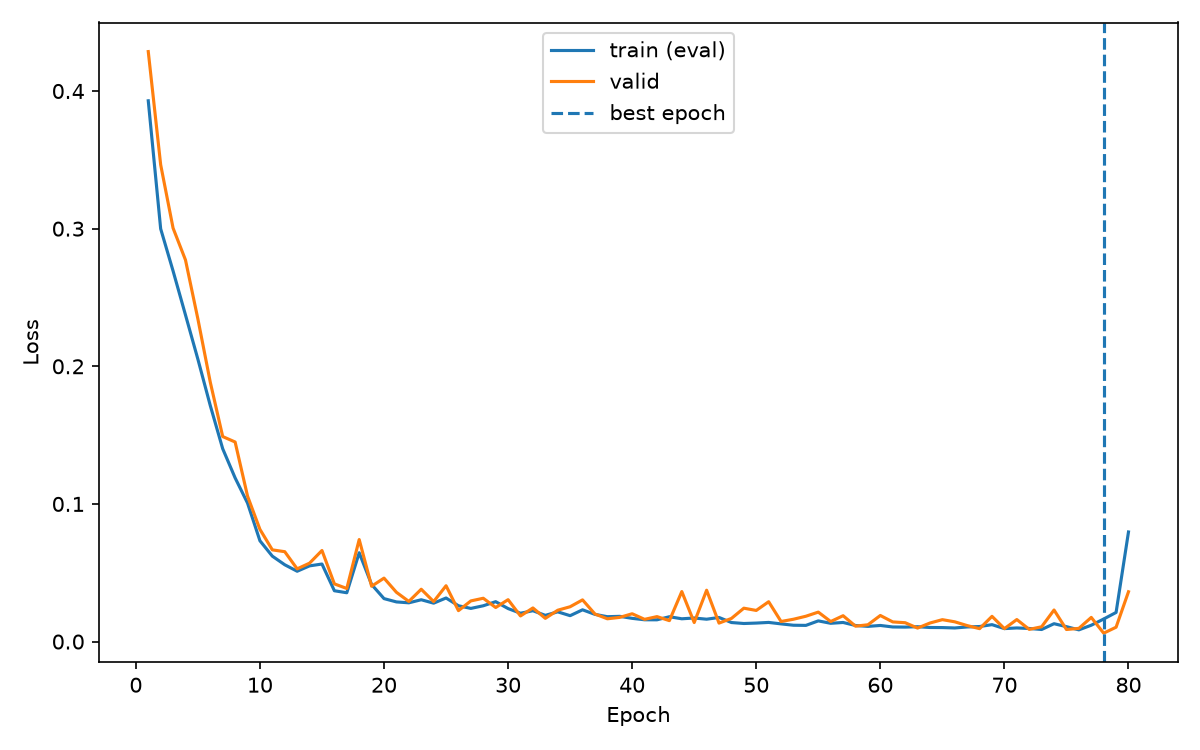

p=0.3


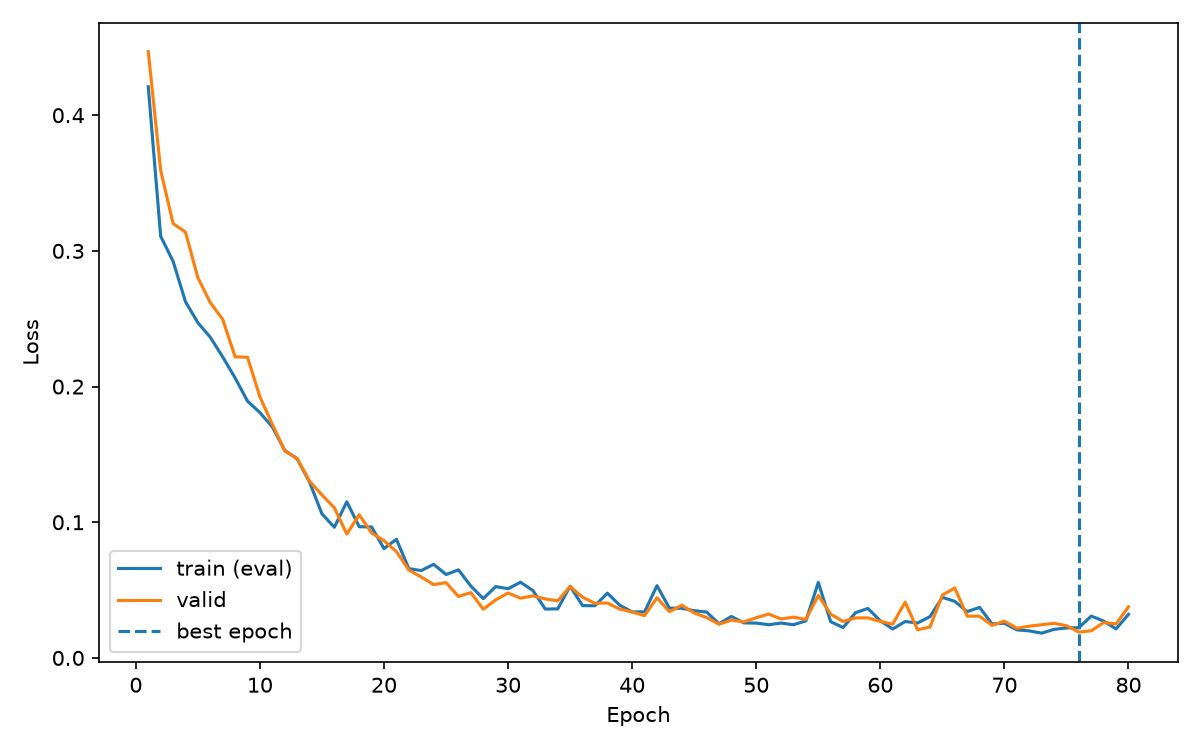

In [5]:
import base64
from IPython.display import Image, display
for p in (0.0, 0.3):
    print(f"p={p}")
    image_path = out / f"05_dropout{p:.1f}_curves.png"
    display(Image(filename=str(image_path)))


## 6. 완료 질문과 다음 확인
**Dropout을 넣었다는 사실과 valid 개선은 같은 말인가?**

아닙니다. Dropout은 규제 방법이며 개선 여부는 고정된 비교 조건에서 측정한 검증 지표로 판단합니다. 이번 측정에서는 p=0이 p=0.3보다 낮은 best valid loss를 보였습니다.

다음에는 여러 seed에서 동일한 비교를 반복하고, best 이후 train·valid 흐름이 지속되는지 확인할 수 있습니다. 학습률 조정, Dropout 확률 변경 등은 한 번에 하나씩 비교하고, test는 설정 선택이 끝난 뒤 최종 평가에 사용합니다.

### 해석 시 점검
- `eval()`은 Dropout을 끄고 `no_grad()`는 기울기 기록을 끕니다. 두 기능을 구분합니다.
- 마지막 epoch의 손실과 best valid loss를 구분합니다.
- best epoch를 찾았다는 이유로 best 모델이 저장되었다고 생각하지 않습니다.
- 위 정적 표는 이번 CPU 실행의 기록입니다. 재실행 결과가 달라지면 코드 출력과 CSV를 기준으로 비교합니다.
